In [163]:
using LowLevelFEM, Plots

In [164]:
openGeometry("beam-3D.geo")
#openPreProcessor()

The hinge coordinates are stored as Gmsh parameters and can be recovered directly from the model. They can be useful later for probing or plotting results at the hinge locations.


## Fields and materials

Each beam segment is associated with a `Material` object. Two unknown fields are introduced:

- `U`: the two-component translational displacement field,
- `Φ`: the scalar rotation field.

The rotation field is created with `reducedOrder=true`, so it is solved in a one-order-lower continuous Lagrange space while assembly and storage remain associated with the original mesh.


In [165]:
mat = Material("beam")
U = Field([mat], type=:VectorField, dim=3, fieldName=:u, rhsName=:f)
Φ = Field([mat], type=:VectorField, dim=3, fieldName=:φ, rhsName=:m, reducedOrder=true);

In [166]:
t = tangentVector(U, "beam")
nξ, nη = normalVectors(U, "beam");


In [167]:
t = [t[1], t[2], t[3]]
nξ = [nξ[1], nξ[2], nξ[3]]
nη = [nη[1], nη[2], nη[3]]

3-element Vector{ScalarField}:
 ScalarField([[0.0; 0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0; 0.0;;]  …  [1.0; 1.0; 1.0; 1.0;;], [1.0; 1.0; 1.0; 1.0;;], [1.0; 1.0; 1.0; 1.0;;], [1.0; 1.0; 1.0; 1.0;;], [1.0; 1.0; 1.0; 1.0;;], [1.0; 1.0; 1.0; 1.0;;], [1.0; 1.0; 1.0; 1.0;;], [1.0; 1.0; 1.0; 1.0;;], [1.0; 1.0; 1.0; 1.0;;], [1.0; 1.0; 1.0; 1.0;;]], Matrix{Float64}(undef, 0, 0), [0.0], [5, 6, 7, 8, 9, 10, 11, 12, 13, 14  …  25, 26, 27, 28, 29, 30, 31, 32, 33, 34], 1, :scalar, Problem("beam-3D", :VectorField, 3, 3, Material[Material("beam", :Hooke, 200000.0, 0.3, 115384.61538461536, 76923.07692307692, 166666.66666666663, 7.85e-9, 45.0, 4.2e8, 1.2e-5, 1.0e-7, 0.1, 1.0)], 1.0, 91, LowLevelFEM.Geometry("", "", 0, 0, nothing, nothing, nothing, nothing), :u, :f, false, :lagrange, LowLevelFEM.ApproximationData(nothing,

## Timoshenko beam kinematics

The generalized beam strain vector is

$$
\boldsymbol{\varepsilon}_b=
\begin{bmatrix}
\varepsilon\\
\gamma\\
\kappa_b
\end{bmatrix},
$$

with axial strain

$$
\varepsilon=\mathbf{t}^T(\nabla\mathbf{u})\mathbf{t},
$$

shear strain

$$
\gamma=\mathbf{n}^T(\nabla\mathbf{u})\mathbf{t}-\varphi,
$$

and curvature

$$
\kappa_b=\nabla\varphi\cdot\mathbf{t}.
$$

The matrices `Au`, `Aφ`, and `Gφ` map the LowLevelFEM operator output to these generalized strain components.


In [168]:
# ------------------------------------------------------------------
# Generalized Timoshenko beam strain
#
# ε = tᵀ ∇u t
# γ = nᵀ ∇u t - φ
# κ = ∇φ ⋅ t
# ------------------------------------------------------------------

Au = vcat(kron(nξ,t)',
          kron(nη,t)',
          kron(t,t)',
          zeros(3,9)
          )

Aφ = vcat(zeros(3,9),
          kron(nξ,t)',
          kron(nη,t)',
          kron(t,t)'
          )

Gφ = vcat(-nη',
          nξ',
          zeros(4,3)
          )

Bu = Au ⋅ Grad(U)

Bφ = Aφ ⋅ Grad(Φ) + Gφ ⋅ Φ;

In [169]:
d = 1
E = mat.E
G = mat.μ
Iξ = d^4 * π / 64
Iη = d^4 * π / 64
Ip = d^4 * π / 32
κ = 4 / 5
A = d^2 * π / 4;

In [170]:
Du = [κ*G*A 0 0
      0 κ*G*A 0
      0  0  E*A]

Dφ = [E*Iξ 0 0
      0 E*Iη 0
      0  0  G*Ip]

D = cat(Du, Dφ, dims=(1,2))

6×6 Matrix{Float64}:
 48332.2      0.0  0.0          0.0      0.0      0.0
     0.0  48332.2  0.0          0.0      0.0      0.0
     0.0      0.0  1.5708e5     0.0      0.0      0.0
     0.0      0.0  0.0       9817.48     0.0      0.0
     0.0      0.0  0.0          0.0   9817.48     0.0
     0.0      0.0  0.0          0.0      0.0   7551.91

In [171]:
B = Bu + Bφ
K = ∫(B' ⋅ D ⋅ B, Γ="beam");
K[:,:]

546×546 SparseArrays.SparseMatrixCSC{Float64, Int64} with 9264 stored entries:
⎡⠿⣧⡘⢧⣄⡀⠈⠓⠀⠛⠀⠀⠀⠒⠀⠶⠂⠀⠀⠰⠿⣅⠸⢥⣄⠀⠐⠃⠐⠛⠀⠀⠀⠒⠀⠖⠀⠀⠀⠶⎤
⎢⠶⣌⠻⢆⡈⠙⠳⠆⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢦⡌⠻⣄⠈⠙⠷⠆⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠹⣆⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢻⡄⠈⠻⣄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⎥
⎢⢦⠀⠹⠆⠀⠈⠱⣦⡀⢤⣄⠀⠀⠀⠀⠀⠀⠀⠀⠀⡄⠀⠹⠀⠀⠈⠳⣤⡀⣤⣀⠀⠀⠀⠀⠀⠀⠀⠀⠀⎥
⎢⣤⠀⠀⠀⠀⠀⠀⣌⠻⣦⡉⠙⠶⠦⠀⠀⠀⠀⠀⠀⡤⠀⠀⠀⠀⠀⠀⣍⠳⣦⠉⠛⠶⠆⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠀⠀⠀⠙⣇⠈⠻⢆⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠻⣆⠈⠷⣄⡀⠀⠀⠀⠀⠀⠀⠀⎥
⎢⢠⠀⠀⠀⠀⠀⠀⠀⠸⡇⠀⠈⠻⣦⡀⢀⣀⠀⠀⠀⣤⠀⠀⠀⠀⠀⠀⠀⢹⡆⠀⠈⠻⣆⡀⣀⣀⠀⠀⠀⎥
⎢⢠⡄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢈⠻⣦⡙⠛⠶⣤⣠⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢘⠻⣌⠙⠛⢦⣤⎥
⎢⠈⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠘⣷⠈⠱⣦⡀⠀⠉⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠸⣦⠉⠳⣦⡀⠀⎥
⎢⢀⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠘⣧⠀⠈⠻⣦⢀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠹⡆⠀⠈⢳⣄⎥
⎢⠟⢧⡈⠷⣤⣀⠀⠉⠀⠋⠀⠀⠀⠛⠀⠚⠃⠀⠀⠐⠿⣧⡘⠷⣤⣀⠈⠁⠘⠋⠀⠀⠀⠛⠀⠛⠀⠀⠀⠒⎥
⎢⠖⣆⠛⢦⡀⠉⠓⠂⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢶⡌⠻⣦⡀⠙⠛⠂⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠙⣆⠀⠛⢦⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢻⣄⠈⠛⣤⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⎥
⎢⠴⠀⠹⠇⠀⠀⠙⣦⡄⢤⣤⡀⠀⠀⠀⠀⠀⠀⠀⠀⠆⠀⠻⠀⠀⠈⠻⣦⡀⢤⣄⡀⠀⠀⠀⠀⠀⠀⠀⠀⎥
⎢⣴⠀⠀⠀⠀⠀⠀⣬⠹⣦⡈⠙⠳⠶⠀⠀⠀⠀⠀⠀⡶⠀⠀⠀⠀⠀⠀⣌⠻⣦⠈⠙⠳⠆⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠀⠀⠀⠘⣧⠀⠙⢧⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠹⣆⠀⠻⣦⡀⠀⠀⠀⠀⠀⠀⠀⎥
⎢⢠⠀⠀⠀⠀⠀⠀⠀⠸⠇⠀⠈⠻⢦⣀⢀⣀⡀⠀⠀⣤⠀⠀⠀⠀⠀⠀⠀⠹⠆⠀⠈⠻⢆⡀⣀⣀⡀⠀⠀⎥
⎢⢠⠄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢨⡛⢦⡌⠛⠳⠦⣤⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢨⠻⣦⡉⠛⠳⠤⎥
⎢⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠘⣷⠀⠹⣦⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠸⣧⠈⠻⣦⡀⠀⎥
⎣⢠⡄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠈⣷⠀⠈⠙⢶⢠⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠙⡆⠀⠈⠱⣦⎦

In [172]:
bc1 = BoundaryCondition("A", field=U, ux=0, uy=0, uz=0)
bc2 = BoundaryCondition("A", field=Φ, φx=0, φy=0, φz=0)

BoundaryCondition("A", Problem("beam-3D", :VectorField, 3, 3, Material[Material("beam", :Hooke, 200000.0, 0.3, 115384.61538461536, 76923.07692307692, 166666.66666666663, 7.85e-9, 45.0, 4.2e8, 1.2e-5, 1.0e-7, 0.1, 1.0)], 1.0, 91, LowLevelFEM.Geometry("", "", 0, 0, nothing, nothing, nothing, nothing), :φ, :m, true, :lagrange, LowLevelFEM.ApproximationData(sparse([1, 40, 43, 2, 41, 44, 3, 42, 45, 13  …  272, 12, 270, 273, 268, 271, 269, 272, 270, 273], [1, 1, 1, 2, 2, 2, 3, 3, 3, 4  …  179, 180, 180, 180, 181, 181, 182, 182, 183, 183], [1.0, 0.22222222222222227, -0.1111111111111111, 1.0, 0.22222222222222227, -0.1111111111111111, 1.0, 0.22222222222222227, -0.1111111111111111, 1.0  …  0.22222222222222215, 1.0, -0.11111111111111112, 0.22222222222222215, 0.8888888888888888, 0.888888888888889, 0.8888888888888888, 0.888888888888889, 0.8888888888888888, 0.888888888888889], 273, 183), sparse([1, 7, 2, 8, 3, 9, 58, 61, 67, 59  …  177, 175, 176, 177, 181, 182, 183, 181, 182, 183], [1, 1, 2, 2, 3, 3

In [173]:
fu = ∫(U ⋅ [0,1,0], Γ="D")
fφ = ∫(Φ ⋅ [0,0,0], Γ="D")

F = SystemVector([fu, fφ]);

In [174]:
u, φ = solveField(K, F, support=[bc1,bc2]);

In [175]:
showDoFResults(fu, name="force", visible=true)
showDoFResults(fφ, name="moment", visible=true)
showDoFResults(u, name="u", factor=2, visible=true);

## Recovery of beam resultants

For post-processing, the local in-plane normal vector is stored as a `VectorField`. The generalized beam strains are then recovered from the solved displacement and rotation fields.


In [176]:
#n = VectorField([nx, ny, 0]);

The displacement field is expanded to the 3D vector representation used by the general gradient and vector-algebra routines. The rotation field is converted to an elementwise field before its gradient is evaluated.

The recovered quantities are

$$
\varepsilon=\mathbf{t}\cdot\left((\nabla\mathbf{u})\mathbf{t}\right),
$$

$$
\gamma=\mathbf{n}\cdot\left((\nabla\mathbf{u})\mathbf{t}\right)-\varphi,
$$

and

$$
\kappa_b=\nabla\varphi\cdot\mathbf{t}.
$$

The corresponding internal forces are

$$
N=EA\varepsilon,
\qquad
T=\kappa_sGA\gamma,
\qquad
M=EI_z\kappa_b.
$$


In [177]:
#u = expandTo3D(u)
φ = nodesToElements(φ)

t = tangentVector(U, "beam")
nξ, nη = normalVectors(U, "beam")

g = ∇(u)

ε = t ⋅ (g * t)
γξ = nξ ⋅ (g * t) - φ ⋅ nη
γη = nη ⋅ (g * t) + φ ⋅ nξ

κξ = nξ ⋅ (∇(φ) * t)
κη = nη ⋅ (∇(φ) * t)
ϑ = t ⋅ (∇(φ) * t)

N = E * A * ε
Tξ = κ * G * A * γξ
Tη = κ * G * A * γη

Mhξ = E * Iξ * κξ
Mhη = E * Iη * κη
Mc = G * Ip * ϑ

elementwise ScalarField
[[-10.000000001771559; -10.000000001771571; -10.000000001771557; -10.000000001771562;;], [-10.00000000177152; -10.000000001771625; -10.000000001771552; -10.000000001771586;;], [-10.000000001771625; -10.000000001771754; -10.000000001771637; -10.00000000177169;;], [-10.000000001771754; -10.000000001771808; -10.00000000177173; -10.000000001771754;;], [-10.000000001771676; -10.000000001771808; -10.000000001771754; -10.000000001771834;;], [-10.000000001771859; -10.000000001771703; -10.000000001771808; -10.000000001771808;;], [-10.000000001771598; -10.000000001771808; -10.000000001771703; -10.000000001771808;;], [-10.000000001771703; -10.000000001771912; -10.000000001771754; -10.000000001771834;;], [-10.000000001772278; -10.000000001772227; -10.000000001771964; -10.000000001772017;;], [-10.000000001772278; -10.000000001772227; -10.000000001772174; -10.000000001772174;;]  …  [-5.502196398601358e-13; -5.240187046287006e-13; -5.371191722444182e-13; -5.429751331308512e-13

In [178]:
showElementResults(t, name="t")
showElementResults(nξ, name="nξ")
showElementResults(nη, name="nη")

5

In [179]:
Tξ0, plotTξ = plotOnBeam("beam", Tξ, name="Tξ graph", plot=true)
Tη0, plotTη = plotOnBeam("beam", Tη, name="Tη graph", plot=true)
N0, plotN = plotOnBeam("beam", N, name="N graph", plot=true)
Mhξ0, plotMhξ = plotOnBeam("beam", Mhξ, name="Mhξ graph", plot=true)
Mhη0, plotMhη = plotOnBeam("beam", Mhη, name="Mhη graph", plot=true)
Mc0, plotMc = plotOnBeam("beam", Mc, name="Mc graph", plot=true);

The returned diagram coordinates can also be processed with an external plotting package if a publication-style figure is preferred.


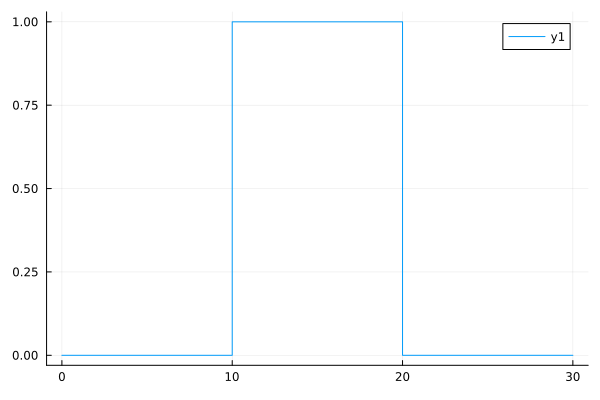

In [180]:
plot(plotN)

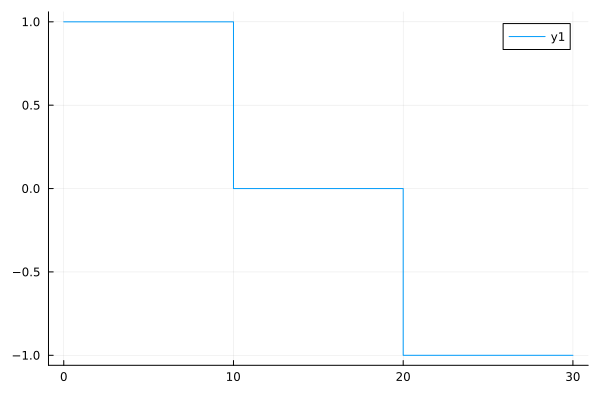

In [181]:
plot(plotTξ)

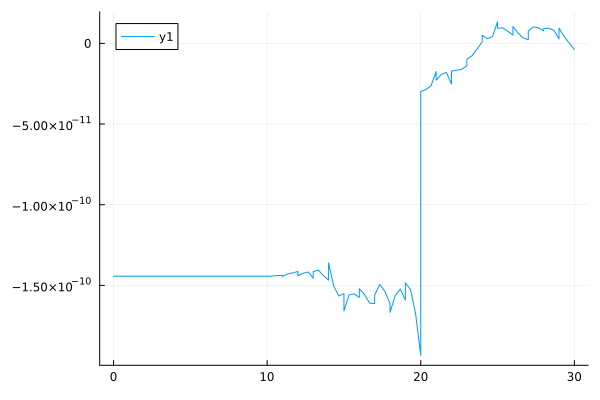

In [182]:
plot(plotTη)

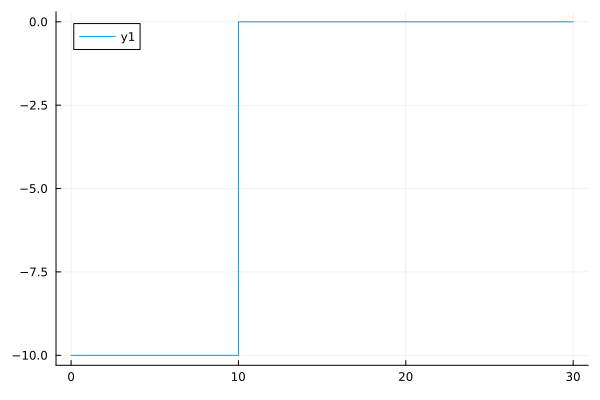

In [183]:
plot(plotMc)

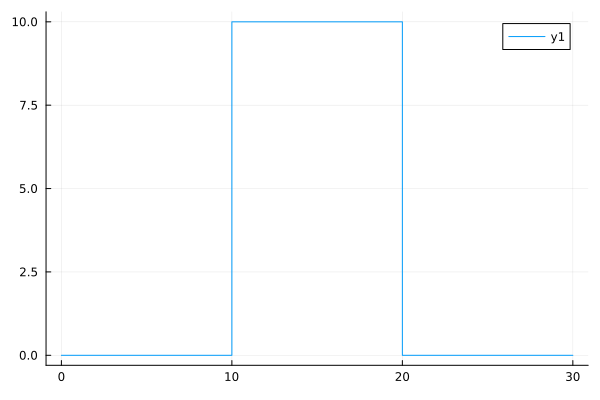

In [184]:
plot(plotMhξ)

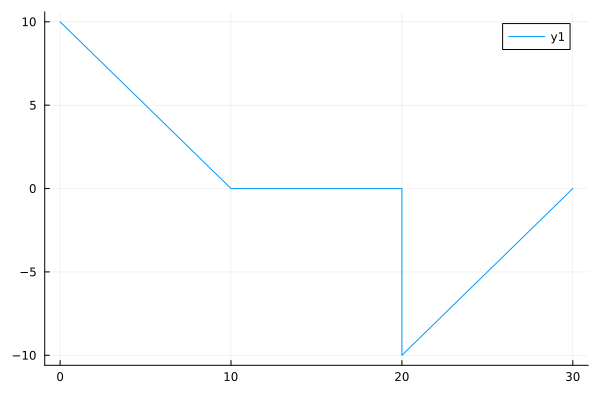

In [185]:
plot(plotMhη)

In [186]:
openPostProcessor()